In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

In [2]:
# ДЗ
# 1. Подберите парамтеры алгоритма разрастания регионов так, чтобы был выделен весь участок газона.
# 2. Реализуйте вычисление критерия однородности, отличного от представленного. Сравните результаты.
# 3. Применить алгоритм сегментации watershed+distance transform для задачи подсчета пальмовых деревьев.

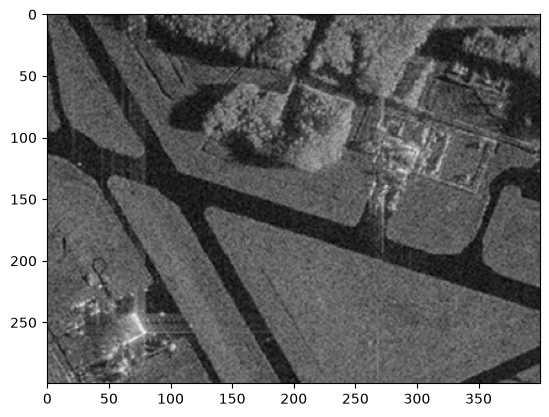

In [3]:
image = cv2.imread('sar_1.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
plt.imshow(image_gray, cmap="gray")
plt.show()

## Задание 1. Разрастание регионов

Алгоритм из практики работает очень долго, потому что на каждом шаге проходит по всем пикселям. Я переписал его: на каждом шаге кандидаты это соседи текущей области (получаю через dilate), и критерий проверяется сразу для всех кандидатов.

In [4]:
def homo_average(img, mask, cand, T):
    av_val = img[mask > 0].mean()
    return np.abs(img[cand].astype(np.float32) - av_val) <= T


def region_growing(image, seed_point, homo_fun, r, T):
    mask = np.zeros(image.shape, np.uint8)
    mask[seed_point] = 1
    kernel = np.ones((2 * r + 1, 2 * r + 1), np.uint8)
    while True:
        cand = np.where((cv2.dilate(mask, kernel) > 0) & (mask == 0))
        ok = homo_fun(image, mask, cand, T)
        if not ok.any():
            break
        mask[cand[0][ok], cand[1][ok]] = 1
    return mask * 255

In [5]:
seed_point = (250, 250)

for r in [1, 2, 3]:
    for T in [10, 15, 20, 25, 30]:
        mask = region_growing(image_gray, seed_point, homo_average, r, T)
        print('r = %d, T = %d, пикселей: %d' % (r, T, np.count_nonzero(mask)))

r = 1, T = 10, пикселей: 16072
r = 1, T = 15, пикселей: 19788
r = 1, T = 20, пикселей: 20914
r = 1, T = 25, пикселей: 21417
r = 1, T = 30, пикселей: 21596
r = 2, T = 10, пикселей: 16120
r = 2, T = 15, пикселей: 19789


r = 2, T = 20, пикселей: 20917
r = 2, T = 25, пикселей: 21417
r = 2, T = 30, пикселей: 21606
r = 3, T = 10, пикселей: 16120
r = 3, T = 15, пикселей: 19794
r = 3, T = 20, пикселей: 20914
r = 3, T = 25, пикселей: 21417
r = 3, T = 30, пикселей: 85867


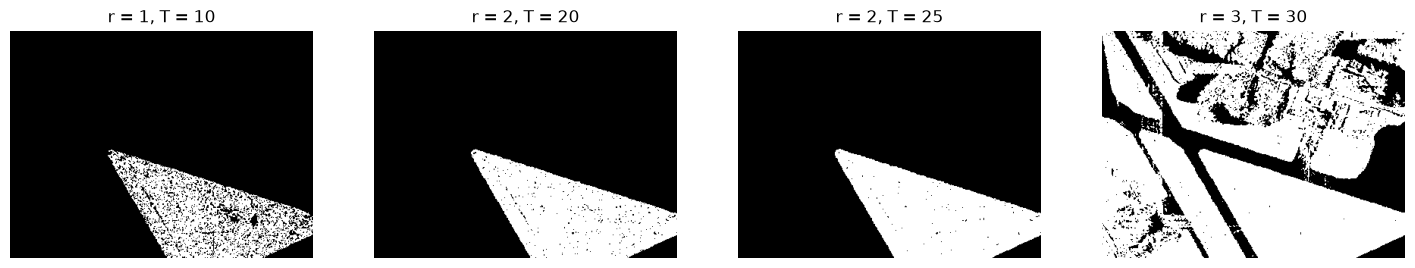

In [6]:
fig, ax = plt.subplots(1, 4, figsize=(18, 4))
for i, (r, T) in enumerate([(1, 10), (2, 20), (2, 25), (3, 30)]):
    mask = region_growing(image_gray, seed_point, homo_average, r, T)
    ax[i].imshow(mask, cmap="gray")
    ax[i].set_title('r = %d, T = %d' % (r, T))
    ax[i].axis('off')
plt.show()

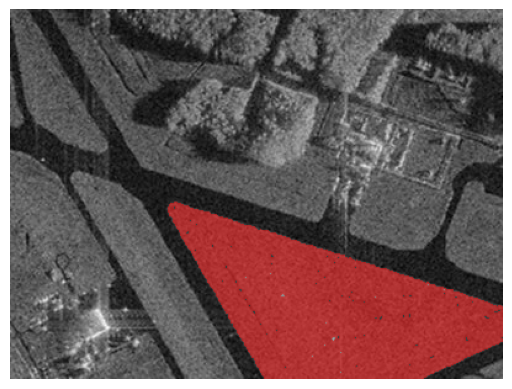

In [7]:
mask_avg = region_growing(image_gray, seed_point, homo_average, 2, 25)

plt.imshow(image_gray, cmap="gray")
plt.imshow(np.ma.masked_where(mask_avg == 0, mask_avg), cmap="autumn", alpha=0.5)
plt.axis('off')
plt.show()

При T от 20 до 25 выделяется весь газон, при T = 10 часть газона не попадает в область. Радиус почти не влияет на результат, только на число итераций. При r = 3 и T = 30 область вылезает через дорогу на соседние участки, поэтому взял r = 2, T = 25.

## Задание 2. Другой критерий однородности

Из за спекл шума отдельные пиксели газона сильно отличаются от среднего, и внутри области остаются дырки. Поэтому в новом критерии сравниваю со средним по области не сам пиксель, а среднее по окну 7x7 вокруг него.

In [8]:
image_local = cv2.blur(image_gray, (7, 7))

def homo_local(img, mask, cand, T):
    av_val = image_local[mask > 0].mean()
    return np.abs(image_local[cand].astype(np.float32) - av_val) <= T

In [9]:
for T in [10, 15, 20, 25, 30]:
    mask = region_growing(image_gray, seed_point, homo_local, 2, T)
    print('T = %d, пикселей: %d' % (T, np.count_nonzero(mask)))

T = 10, пикселей: 20096
T = 15, пикселей: 20830
T = 20, пикселей: 21188
T = 25, пикселей: 21521
T = 30, пикселей: 21930


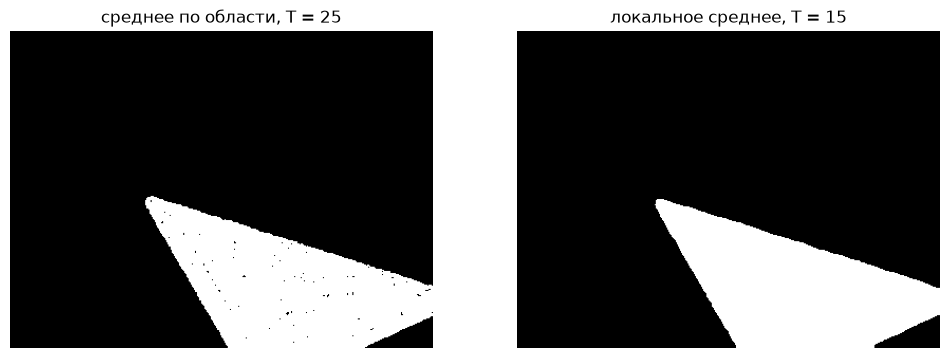

дырок внутри (avg): 126
дырок внутри (local): 0


In [10]:
mask_local = region_growing(image_gray, seed_point, homo_local, 2, 15)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].imshow(mask_avg, cmap="gray")
ax[0].set_title('среднее по области, T = 25')
ax[1].imshow(mask_local, cmap="gray")
ax[1].set_title('локальное среднее, T = 15')
for a in ax:
    a.axis('off')
plt.show()

print('дырок внутри (avg):', np.count_nonzero(cv2.morphologyEx(mask_avg, cv2.MORPH_CLOSE, np.ones((5, 5), np.uint8)) - mask_avg))
print('дырок внутри (local):', np.count_nonzero(cv2.morphologyEx(mask_local, cv2.MORPH_CLOSE, np.ones((5, 5), np.uint8)) - mask_local))

С локальным средним газон выделяется сплошной областью без дырок, и результат почти не зависит от T (от 10 до 30 площадь меняется мало). С обычным критерием внутри остаются отдельные точки, которые не прошли порог.

## Задание 3. Подсчет пальм

Кроны пальм светлее, чем промежутки между ними, но освещение неравномерное, поэтому вместо Отсу использую адаптивный порог.

In [11]:
palms = cv2.imread('palm_1.JPG')
gray = cv2.cvtColor(palms, cv2.COLOR_BGR2GRAY)
blur = cv2.GaussianBlur(gray, (21, 21), 0)

thresh = cv2.adaptiveThreshold(blur, 255, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY, 61, 0)
thresh = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, np.ones((7, 7), np.uint8))

dist = cv2.distanceTransform(thresh, cv2.DIST_L2, 5)

In [12]:
# как порог по distance transform влияет на число найденных пальм
for k in [0.2, 0.3, 0.4, 0.5]:
    _, fg = cv2.threshold(dist, k * dist.max(), 255, cv2.THRESH_BINARY)
    n, _ = cv2.connectedComponents(fg.astype(np.uint8))
    print('k = %.1f: %d' % (k, n - 1))

k = 0.2: 101
k = 0.3: 90
k = 0.4: 87
k = 0.5: 78


In [13]:
_, sure_fg = cv2.threshold(dist, 0.3 * dist.max(), 255, cv2.THRESH_BINARY)
sure_fg = sure_fg.astype(np.uint8)
unknown = cv2.subtract(thresh, sure_fg)

n, markers = cv2.connectedComponents(sure_fg)
markers = markers + 1
markers[unknown == 255] = 0
markers = cv2.watershed(palms, markers)

res = palms.copy()
res[markers == -1] = (0, 0, 255)
count = 0
for i in range(2, n + 1):
    ys, xs = np.where(markers == i)
    if len(xs) > 0:
        count += 1
        cv2.circle(res, (int(xs.mean()), int(ys.mean())), 4, (255, 0, 0), -1)
print('найдено пальм:', count)

найдено пальм: 89


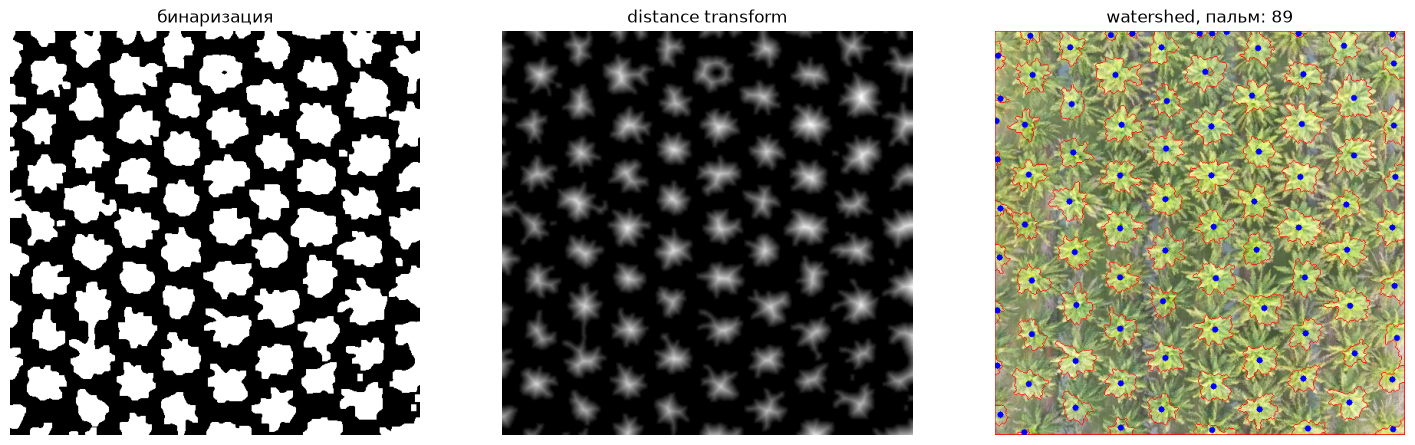

In [14]:
fig, ax = plt.subplots(1, 3, figsize=(18, 6))
ax[0].imshow(thresh, cmap="gray")
ax[0].set_title('бинаризация')
ax[1].imshow(dist, cmap="gray")
ax[1].set_title('distance transform')
ax[2].imshow(cv2.cvtColor(res, cv2.COLOR_BGR2RGB))
ax[2].set_title('watershed, пальм: %d' % count)
for a in ax:
    a.axis('off')
plt.show()

## Вывод

Для выделения газона достаточно критерия по среднему с r = 2 и T = 20...25. Если порог слишком маленький, выделяется только часть газона, если слишком большой (r = 3, T = 30), область проходит через дорогу и площадь вырастает в 4 раза.

Критерий по локальному среднему лучше подходит для SAR снимка: область получается сплошной (0 дырок против 126) и меньше зависит от выбора T.

Watershed с distance transform нашел 89 пальм. Результат зависит от порога по distance transform: при меньшем пороге соседние кроны начинают делиться на части, при большем мелкие и темные пальмы пропадают. Часть ошибок дают пальмы, обрезанные краем изображения.